# Backtest de EAD por tramo de utilización y la batería de validación de LGD y EAD

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 03 y 05 de este tema (la escalera de LGD y los estimadores de CCF)
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- hacer el backtest de un modelo de EAD en moneda por tramo de utilización con `ead_backtest_by_band`, calcular a mano las brechas por tramo, y leer su métrica, su estadístico y su luz;
- reproducir el backtest versionado de los ocho modelos de EAD de C09 a partir de los totales por tramo que guarda el artefacto, y ver qué modelo falla en qué tramo;
- correr las tres pruebas de LGD del motor, `lgd_calibration_by_segment`, `lgd_calibration_over_time` y `lgd_discrimination`, calcular a mano sus estadísticos sobre un ejemplo pequeño y leer sus luces;
- leer la batería de LGD versionada de C08 para la cohorte 2014-19, verificar su ajuste de Bonferroni desde las filas que guarda, y decir por qué la calibración y la discriminación pueden discrepar.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation import lgd_ead as tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Tres artefactos versionados. `data/derived/C09/level-3.json` es el generador de líneas rotativas del caso C09 con nivel de aceleración 3 (una verdad conocida: líneas sintéticas, no de ningún prestamista), con el backtest de ocho modelos de EAD por tramo de utilización en `outputs.ead_backtest`. `data/derived/C08/dc-2014-19.json` es la variante de C08 para los incumplimientos de 2014 a 2019 (un proxy de castigos sobre los préstamos a pequeñas empresas SBA 7(a), cuaderno 01), con las pruebas de LGD de los seis peldaños de la escalera en `tests`. El tercero, `data/derived/C08/dc-2020-23.json`, se lee solo por su número de préstamos en el paso 6. Fueron horneados con un motor anterior al instalado, y la celda siguiente imprime las versiones.

Las pruebas de LGD y EAD del motor son funciones simples cuyas luces son **umbrales internos de Contraste, no umbrales regulatorios** (sus docstrings lo dicen): cada una enuncia su regla, y el pipeline registra los parámetros con el resultado.

In [2]:
# Abrir los dos artefactos e imprimir las versiones que los hornearon, los tramos y los modelos del backtest
ROOT = Path("../../..").resolve()
c09 = json.loads((ROOT / "data" / "derived" / "C09" / "level-3.json").read_text(encoding="utf-8"))
c08 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2014-19.json").read_text(encoding="utf-8"))
backtest = c09["outputs"]["ead_backtest"]
print("C09:", c09["provenance"]["riskvalidation_version"], "| C08:", c08["provenance"]["riskvalidation_version"], "| instalado:", rv.__version__)
print("tramos de utilización:", backtest["bands"], "|", backtest["currency"])
print("modelos con backtest:", sorted({r["model_id"] for r in backtest["rows"]}))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluado"}

C09: 0.6.0 | C08: 0.6.0 | instalado: 0.9.0
tramos de utilización: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 4.0] | USD
modelos con backtest: ['ccf-cohort-floor-cap', 'ccf-fixed-horizon-bounded-scale', 'ccf-fixed-horizon-censor', 'ccf-fixed-horizon-floor-cap', 'ccf-fixed-horizon-none', 'ccf-variable-horizon-floor-cap', 'direct-ead', 'utilisation-change']


## Método

### Paso 1: el backtest de EAD por tramo, a mano

Un modelo de EAD se juzga en moneda, no solo como un factor (la investigación sigue en esto a Tong et al. 2016 y Qi 2009). El motor agrupa las líneas por tramo de utilización $[u_b, u_{b+1})$ (el último tramo es cerrado) y, para cada tramo $b$ con EAD predichas $\hat{E}_i$ y EAD realizadas $E_i$:

$$\text{brecha}_b = \sum_{i \in b}\hat{E}_i - \sum_{i \in b}E_i, \qquad \text{brecha relativa}_b = \frac{\text{brecha}_b}{\sum_{i \in b}E_i}, \qquad \text{métrica} = \max_b |\text{brecha relativa}_b|$$

El estadístico es la brecha relativa del total. La luz es un umbral interno de Contraste: verde cuando la métrica es a lo más 0.10, ámbar hasta 0.25, rojo sobre eso (`gap_amber` y `gap_red`, registrados con el resultado; el valor p es nulo). Un tramo sin líneas, o con una EAD realizada de cero, no entra en la métrica. (Todo del docstring de `ead_backtest_by_band`.)

La celda inventa seis líneas en tres tramos, calcula cada tramo a mano y corre el motor sobre los mismos arreglos.

In [3]:
# Seis líneas inventadas en tres tramos de utilización: las brechas por tramo a mano y luego ead_backtest_by_band del motor
utilisation = np.array([0.10, 0.15, 0.30, 0.35, 0.60, 0.90])
predicted = np.array([1_000.0, 1_200.0, 2_000.0, 2_200.0, 4_000.0, 5_000.0])
realised = np.array([1_100.0, 1_150.0, 2_500.0, 2_400.0, 3_600.0, 4_700.0])
edges = np.array([0.0, 0.2, 0.4, 1.0])
relative = []
for b in range(3):
    inside = (utilisation >= edges[b]) & ((utilisation < edges[b + 1]) | (b == 2))
    gap = predicted[inside].sum() - realised[inside].sum()
    relative.append(gap / realised[inside].sum())
    print(f"tramo [{edges[b]}, {edges[b + 1]}): n={inside.sum()} predicha {predicted[inside].sum():8.1f} realizada {realised[inside].sum():8.1f} brecha {gap:8.1f} brecha relativa {gap / realised[inside].sum():8.4f}")
print(f"métrica a mano (máxima brecha relativa absoluta): {max(abs(r) for r in relative):.4f} | brecha relativa del total: {(predicted.sum() - realised.sum()) / realised.sum():.4f}")
res = tests.ead_backtest_by_band(predicted, realised, utilisation, edges, model_id="inventado")
print(f"motor: métrica {res.metric:.4f} | estadístico {res.statistic:.4f} | luz: {LIGHT[res.light.value]} | {res.policy_version}")

tramo [0.0, 0.2): n=2 predicha   2200.0 realizada   2250.0 brecha    -50.0 brecha relativa  -0.0222
tramo [0.2, 0.4): n=2 predicha   4200.0 realizada   4900.0 brecha   -700.0 brecha relativa  -0.1429
tramo [0.4, 1.0): n=2 predicha   9000.0 realizada   8300.0 brecha    700.0 brecha relativa   0.0843
métrica a mano (máxima brecha relativa absoluta): 0.1429 | brecha relativa del total: -0.0032
motor: métrica 0.1429 | estadístico -0.0032 | luz: ámbar | contraste-lgd-ead-battery-1.0.0; gap_amber=0.1; gap_red=0.25


### Paso 2: el backtest versionado, reproducido desde sus totales por tramo

El artefacto C09 no guarda las 50.000 líneas de cada réplica, pero guarda de lo que está hecho el backtest: para cada modelo y tramo, el número de incumplidores, la EAD predicha y la realizada en USD, la brecha y la brecha relativa. La métrica del motor depende solo de esos totales por tramo, así que la función se puede correr sobre ellos: una pseudo-línea por tramo, puesta en el medio del tramo, con los totales predicho y realizado del tramo. El resultado debe igualar la métrica, el estadístico y la luz versionados. La celda siguiente lo hace para los ocho modelos e imprime la coincidencia, con la versión que horneó las filas versionadas junto a la instalada (difieren, así que la coincidencia es una verificación real).

In [4]:
# Correr ead_backtest_by_band sobre los totales por tramo de cada modelo versionado y comparar con la métrica, el estadístico y la luz versionados
committed = {t["model_id"]: t for t in c09["tests"] if t["test_id"] == "lgd_ead.ead_backtest_by_band"}
bands = np.array(backtest["bands"])
print("filas versionadas horneadas con", c09["provenance"]["riskvalidation_version"], "| recalculado con", rv.__version__)
print(f"{'modelo':34s} {'métrica':>9s} {'versionado':>11s} {'luz':>8s} {'versionado':>11s} {'peor tramo':>14s} {'coincide':>9s}")
all_match = True
for model_id, row in committed.items():
    rows = [r for r in backtest["rows"] if r["model_id"] == model_id]
    mid = np.array([(r["utilisation_lower"] + r["utilisation_upper"]) / 2 for r in rows])
    out = tests.ead_backtest_by_band(np.array([r["predicted_ead"] for r in rows]), np.array([r["realised_ead"] for r in rows]), mid, bands, model_id=model_id)
    worst = max(rows, key=lambda r: abs(r["relative_gap"]))
    match = bool(np.isclose(out.metric, row["metric"], atol=1e-8)) and out.light.value == row["light"] and bool(np.isclose(out.statistic, row["statistic"], atol=1e-8))
    all_match &= match
    print(f"{model_id:34s} {out.metric:9.4f} {row['metric']:11.4f} {LIGHT[out.light.value]:>8s} {LIGHT[row['light']]:>11s} {worst['band_id']:>6s} ({worst['relative_gap']:+.3f}) {si_no(match)!s:>9s}")
print("los ocho reproducidos:", si_no(all_match))

filas versionadas horneadas con 0.6.0 | recalculado con 0.9.0
modelo                               métrica  versionado      luz  versionado     peor tramo  coincide
ccf-fixed-horizon-none                0.0230      0.0230    verde       verde     u1 (+0.023)        sí
ccf-fixed-horizon-censor              0.0476      0.0476    verde       verde     u1 (-0.048)        sí
ccf-fixed-horizon-floor-cap           0.0190      0.0190    verde       verde     u3 (-0.019)        sí
ccf-fixed-horizon-bounded-scale       0.0156      0.0156    verde       verde     u7 (-0.016)        sí
ccf-cohort-floor-cap                  0.2033      0.2033    ámbar       ámbar     u1 (+0.203)        sí
ccf-variable-horizon-floor-cap        0.0305      0.0305    verde       verde     u2 (+0.031)        sí
direct-ead                            0.5719      0.5719     rojo        rojo     u7 (-0.572)        sí
utilisation-change                    0.2195      0.2195    ámbar       ámbar     u5 (+0.219)        sí
los

### Paso 3: dónde fallan los modelos

Una sola métrica esconde dónde. La figura dibuja la brecha relativa por tramo para tres de los modelos: el modelo de CCF a horizonte fijo con piso y tope, el modelo de EAD directo y el modelo de cambio de utilización. Los tramos son de utilización (la parte usada del límite) en la fecha de referencia, así que los tramos de la derecha contienen líneas que ya estaban totalmente usadas o sobre su límite.

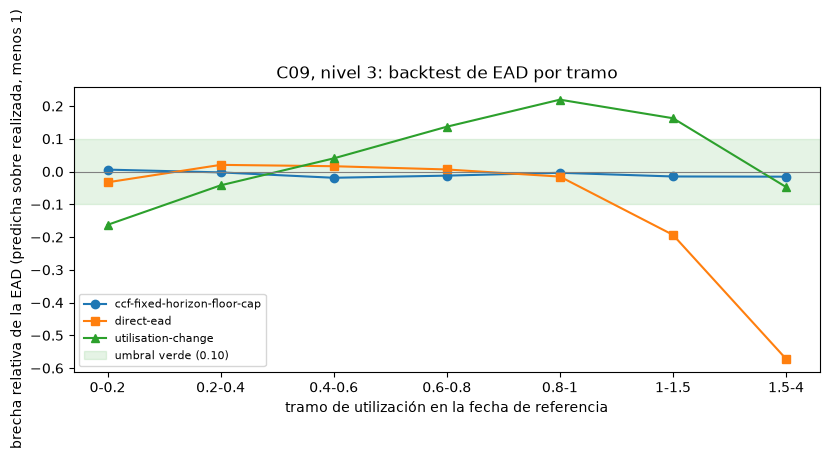

In [5]:
# Dibujar la brecha relativa por tramo de utilización para tres de los ocho modelos de EAD
fig, ax = plt.subplots(figsize=(8.4, 3.8))
labels = [f"{lo:g}-{hi:g}" for lo, hi in zip(bands[:-1], bands[1:])]
for model_id, marker in (("ccf-fixed-horizon-floor-cap", "o"), ("direct-ead", "s"), ("utilisation-change", "^")):
    rows = [r for r in backtest["rows"] if r["model_id"] == model_id]
    ax.plot(range(len(rows)), [r["relative_gap"] for r in rows], marker=marker, label=model_id)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.axhspan(-0.10, 0.10, color="tab:green", alpha=0.12, label="umbral verde (0.10)")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_xlabel("tramo de utilización en la fecha de referencia")
ax.set_ylabel("brecha relativa de la EAD (predicha sobre realizada, menos 1)")
ax.set_title("C09, nivel 3: backtest de EAD por tramo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Paso 4: las tres pruebas de LGD sobre un ejemplo pequeño, a mano

Las pruebas de LGD del motor toman la LGD realizada y la predicha de cada préstamo. La celda inventa doce préstamos (valores realizados y predichos escritos) para que cada intermedio sea visible, y calcula a mano lo que calculan la primera y la tercera prueba:

- `lgd_calibration_by_segment`: una prueba t pareada de la brecha $d_i = \text{realizada}_i - \text{predicha}_i$, $t = \bar d / (s_d / \sqrt{N})$ con $N - 1$ grados de libertad y un valor p de dos colas; la métrica es $\bar d$; la luz es verde cuando el valor p es al menos 0.05, ámbar desde 0.01 y rojo bajo eso.
- `lgd_discrimination`: la correlación de rangos de Spearman $\rho$ de la LGD predicha y la realizada, que es la correlación de Pearson de los rangos (empates por rango promedio); la luz es verde cuando $\rho \ge 0.30$, ámbar desde 0.10, rojo bajo eso, un umbral de Contraste, porque el poder de ordenamiento de la LGD es modesto en la literatura.

(Las reglas y umbrales son los de los docstrings de las dos funciones.) El valor p del estadístico t viene del motor, que usa la distribución t; el cuaderno calcula el estadístico por su cuenta.

In [6]:
# Doce préstamos inventados: el estadístico t pareado y la correlación de Spearman a mano, luego las dos pruebas del motor
real = np.array([0.55, 0.70, 0.40, 0.90, 0.62, 0.35, 0.80, 0.58, 0.66, 0.48, 0.75, 0.52])
pred = np.array([0.50, 0.60, 0.45, 0.70, 0.61, 0.40, 0.65, 0.55, 0.52, 0.51, 0.62, 0.47])
d = real - pred
n = d.size
mean_d, sd_d = d.mean(), d.std(ddof=1)
se = sd_d / np.sqrt(n)
print(f"N={n} | brecha media {mean_d:.4f} | desviación estándar de las brechas {sd_d:.4f} | error estándar {se:.4f} | t = {mean_d / se:.4f}")
rank = lambda x: np.argsort(np.argsort(x)) + 1.0
rho = np.corrcoef(rank(real), rank(pred))[0, 1]
print(f"rangos de los valores realizados: {rank(real).astype(int).tolist()}")
print(f"rangos de los valores predichos: {rank(pred).astype(int).tolist()} | Spearman a mano = {rho:.4f}")

by_segment = tests.lgd_calibration_by_segment(real, pred, segment="inventado")
rank_test = tests.lgd_discrimination(real, pred, segment="inventado")
print(f"lgd_calibration_by_segment: t={by_segment.statistic:.4f} p={by_segment.p_value:.4f} métrica={by_segment.metric:.4f} intervalo al 95% de la brecha media=({by_segment.extras['ci_low']:.4f}, {by_segment.extras['ci_high']:.4f}) luz: {LIGHT[by_segment.light.value]}")
print(f"lgd_discrimination:         rho={rank_test.statistic:.4f} p={rank_test.p_value:.4g} luz: {LIGHT[rank_test.light.value]}")

N=12 | brecha media 0.0608 | desviación estándar de las brechas 0.0834 | error estándar 0.0241 | t = 2.5271
rangos de los valores realizados: [5, 9, 2, 12, 7, 1, 11, 6, 8, 3, 10, 4]
rangos de los valores predichos: [4, 8, 2, 12, 9, 1, 11, 7, 6, 5, 10, 3] | Spearman a mano = 0.9441
lgd_calibration_by_segment: t=2.5271 p=0.0281 métrica=0.0608 intervalo al 95% de la brecha media=(0.0079, 0.1138) luz: ámbar
lgd_discrimination:         rho=0.9441 p=3.927e-06 luz: verde


### Paso 5: los mismos préstamos en el tiempo

`lgd_calibration_over_time(realised, predicted, period)` corre la prueba t pareada dentro de cada período (un año de incumplimiento o un índice de cohorte), conserva los períodos con al menos dos observaciones y dispersión no nula, y los combina:

$$\text{estadístico} = \max_k |t_k|, \qquad p = \min\big(1,\; K\,\min_k p_k\big), \qquad \text{métrica} = \max_k |\bar d_k|$$

con $K$ el número de períodos probados (un ajuste de Bonferroni, para que mirar varios períodos no infle la probabilidad de una falsa alarma). Un período con dispersión nula y una brecha distinta de cero deja la luz en rojo. La celda asigna los doce préstamos a tres años de cuatro, corre la prueba y comprueba el ajuste desde las filas por período que devuelve el motor.

In [7]:
# Correr lgd_calibration_over_time sobre los doce préstamos en tres años y comprobar el ajuste de Bonferroni desde sus filas por período
period = np.repeat([2019, 2020, 2021], 4)
over_time = tests.lgd_calibration_over_time(real, pred, period, model_id="inventado")
for row in over_time.extras["periods"]:
    print(f"período {row['period']}: n={row['n']} brecha media {row['mean_gap']:.4f} t={row['t']:.4f} p={row['p']:.4f}")
k = over_time.extras["n_periods_tested"]
print(f"K={k} | estadístico (mayor |t|) {over_time.statistic:.4f} | p = min(1, K * min p) = {min(1.0, k * min(r['p'] for r in over_time.extras['periods'])):.4f} | p del motor {over_time.p_value:.4f} | luz: {LIGHT[over_time.light.value]}")

período 2019: n=4 brecha media 0.0750 t=1.4412 p=0.2452
período 2020: n=4 brecha media 0.0350 t=0.8347 p=0.4651
período 2021: n=4 brecha media 0.0725 t=1.8280 p=0.1650
K=3 | estadístico (mayor |t|) 1.8280 | p = min(1, K * min p) = 0.4950 | p del motor 0.4950 | luz: verde


### Paso 6: la batería de LGD versionada de C08, 2014-19

La variante de C08 guarda las filas de pruebas del motor para cada peldaño de la escalera: calibración por segmento (toda la cohorte es el segmento), discriminación, y calibración en el tiempo. La prueba en el tiempo de una variante por corte corre sobre todos los incumplimientos posteriores al corte de entrenamiento, así que sus períodos son los años de incumplimiento y su número de préstamos es mayor que el de la cohorte; la celda comprueba esa cifra. Luego imprime, para los seis peldaños, la brecha media con su valor p y luz, la correlación de Spearman con su luz y el estadístico en el tiempo, y verifica el ajuste de Bonferroni desde las filas por período guardadas del peldaño de logit fraccional.

In [8]:
# Imprimir la batería versionada de los seis peldaños para la cohorte 2014-19 y verificar el ajuste de Bonferroni desde las filas por período guardadas
rows = {(t["model_id"], t["test_id"].split(".")[1]): t for t in c08["tests"] if t["model_id"]}
n_cohort = c08["outputs"]["lgd_distribution"]["n"]
over = rows[("L2-fractional-logit", "lgd_calibration_over_time")]
c08_2020 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2020-23.json").read_text(encoding="utf-8"))["outputs"]["lgd_distribution"]["n"]
print(f"préstamos de la cohorte 2014-19: {n_cohort:,} | en la cohorte 2020-23: {c08_2020:,} | préstamos de la prueba en el tiempo: {over['n']:,} | suma de las dos cohortes: {n_cohort + c08_2020:,}")
print("horneado con riskvalidation:", c08["provenance"]["riskvalidation_version"])
print(f"{'peldaño':22s} {'brecha media':>12s} {'p':>10s} {'luz':>8s} | {'Spearman':>8s} {'luz':>8s} | {'max |t| por año':>18s} {'luz':>8s}")
for rung in sorted({k[0] for k in rows}):
    a, b, c = (rows[(rung, name)] for name in ("lgd_calibration_by_segment", "lgd_discrimination", "lgd_calibration_over_time"))
    print(f"{rung:22s} {a['metric']:12.4f} {a['p_value']:10.2e} {LIGHT[a['light']]:>8s} | {b['metric']:8.4f} {LIGHT[b['light']]:>8s} | {c['statistic']:18.3f} {LIGHT[c['light']]:>8s}")
periods = over["extras"]["periods"]
k_tested = len(periods)
print()
print(f"logit fraccional: períodos probados K={k_tested} | min p = {min(r['p'] for r in periods):.3e} | K * min p = {k_tested * min(r['p'] for r in periods):.3e} | p versionado = {over['p_value']:.3e}")

préstamos de la cohorte 2014-19: 36,481 | en la cohorte 2020-23: 13,930 | préstamos de la prueba en el tiempo: 50,411 | suma de las dos cohortes: 50,411
horneado con riskvalidation: 0.6.0
peldaño                brecha media          p      luz | Spearman      luz |    max |t| por año      luz
L1-ols                       0.0058   8.46e-05     rojo |   0.4390    verde |              7.066     rojo
L2-fractional-logit          0.0164   4.37e-28     rojo |   0.4399    verde |             10.799     rojo
L3-beta                      0.0138   2.88e-20     rojo |   0.4257    verde |              9.555     rojo
L4-hurdle                    0.0165   1.45e-28     rojo |   0.4405    verde |             10.845     rojo
L5-gradient-boosted          0.0300   1.85e-96     rojo |   0.5139    verde |             17.831     rojo
L6-tobit                     0.0167   1.88e-29     rojo |   0.4376    verde |              9.229     rojo

logit fraccional: períodos probados K=10 | min p = 4.991e-27 | K * mi

La brecha media es positiva para todos los peldaños y la luz de calibración es roja para todos, mientras que la correlación de Spearman está sobre el umbral verde en todos ellos: los modelos ordenan los préstamos de forma aceptable y ubican su nivel demasiado bajo. La última figura muestra la brecha por año de incumplimiento del peldaño de logit fraccional, que es donde la prueba en el tiempo encuentra su mayor t.

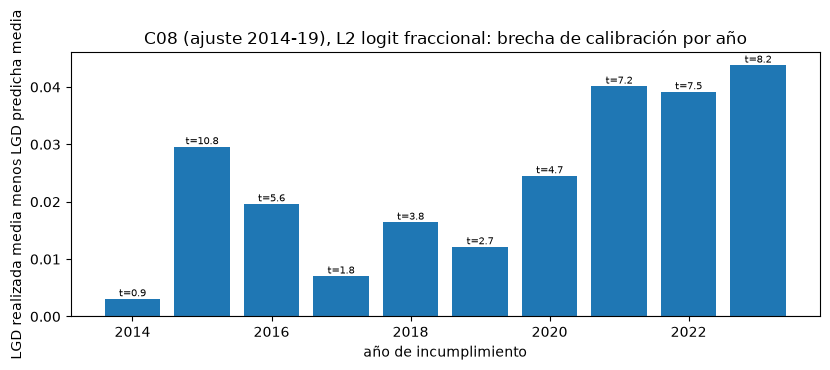

In [9]:
# Dibujar la brecha media por año de incumplimiento del peldaño de logit fraccional, con el estadístico t de cada año en las etiquetas
fig, ax = plt.subplots(figsize=(8.4, 3.6))
years = [r["period"] for r in periods]
ax.bar(years, [r["mean_gap"] for r in periods], color="tab:blue")
for r in periods:
    ax.annotate(f"t={r['t']:.1f}", (r["period"], r["mean_gap"]), ha="center", va="bottom", fontsize=7)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("año de incumplimiento")
ax.set_ylabel("LGD realizada media menos LGD predicha media")
ax.set_title("C08 (ajuste 2014-19), L2 logit fraccional: brecha de calibración por año")
fig.tight_layout()
plt.show()

## Resultados

- **El backtest es una fórmula trabajada.** En las seis líneas inventadas las brechas por tramo son -0,0222, -0,1429 y 0,0843, así que la métrica es 0,1429 (ámbar) y la brecha relativa del total es solo -0,0032: un total puede verse bien mientras un tramo está mal. El motor devuelve los mismos números.
- **El backtest versionado se reproduce exactamente.** El motor, corrido sobre los totales por tramo que guarda el artefacto, da la métrica, el estadístico y la luz versionados para los ocho modelos de C09 en el nivel 3, aunque las filas versionadas fueron horneadas con el motor 0.6.0 y este cuaderno corre la 0.8.1.
- **Los modelos fallan en lugares distintos.** Los modelos de factor a horizonte fijo están en verde (métricas de 0,0156 a 0,0476) y el de horizonte variable también (0,0305). El diseño de cohorte está en ámbar con 0,2033, peor en el tramo más bajo (+0,203). El modelo de cambio de utilización está en ámbar con 0,2195, peor en el tramo de 0,8 a 1,0. El modelo de EAD directo está en rojo con 0,5719, peor en el tramo más alto, de 1,5 a 4,0 (-0,572), las líneas sobre su límite que no puede predecir.
- **Toda prueba de LGD se puede calcular a mano.** En los doce préstamos inventados la brecha media es 0,0608 con una desviación estándar de 0,0834 y un error estándar de 0,0241, así que t = 2,5271 y el valor p del motor es 0,0281 (ámbar); la correlación de Spearman es 0,9441 a mano y con el motor (verde).
- **La prueba en el tiempo es un máximo con ajuste de Bonferroni.** Con tres períodos el mayor |t| es 1,8280 y el valor p ajustado 0,4950, que es tres veces el menor valor p por período.
- **C08, 2014-19: la calibración es roja para todos los peldaños y la discriminación es verde para todos.** Las brechas medias van de 0,0058 a 0,0300 con valores p de 8,46e-05 a 1,85e-96, las correlaciones de Spearman de 0,4257 a 0,5139, y los estadísticos en el tiempo de 7,066 a 17,831. La luz la fija el valor p, no el tamaño de la brecha: con 36.481 préstamos una brecha de 0,0058 ya es roja. La prueba en el tiempo cubre 50.411 préstamos, la suma de las cohortes 2014-19 y 2020-23, y su ajuste cuadra con las filas guardadas (K = 10, 10 por 4,991e-27 es igual al 4,991e-26 versionado).

Lo que el cuaderno no hace: no recalcula las réplicas de C09 ni las filas de LGD por préstamo de C08, que no se versionan; donde recalcula un resultado versionado lo hace desde los totales por tramo guardados. Los préstamos y líneas inventados muestran solo la aritmética.

## Resumen

- Un modelo de EAD se prueba en moneda por tramo de utilización: las brechas por tramo, su tamaño relativo, y la mayor de ellas como métrica, con un umbral verde en 0.10 y uno rojo en 0.25 que son propios de Contraste.
- El backtest versionado de los ocho modelos de C09 lo reproduce exactamente el motor solo desde los totales por tramo, lo que es una verificación del artefacto contra el motor instalado.
- Las pruebas de LGD son un t pareado sobre la brecha media, una correlación de Spearman contra umbrales fijos, y un t pareado en el tiempo con ajuste de Bonferroni; cada una se puede calcular a mano sobre un ejemplo pequeño.
- En C08 la luz de calibración es roja para todos los peldaños mientras la discriminación es verde: calibración y ordenamiento son preguntas distintas, y la batería hace ambas.

**Qué probar a continuación.** Cambia las EAD predichas del paso 1 para que un tramo pase de verde a ámbar y luego a rojo; luego sigue con el cuaderno 07, que pone los resultados de C08 y C09 junto a la evidencia comparada de la literatura.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk: el documento detrás de las pruebas de PD del tema 01; las pruebas de LGD y EAD de este cuaderno siguen los docstrings y umbrales propios del motor. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- Tong, E. N. C., Mues, C., Brown, I. y Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3). https://doi.org/10.1016/j.ejor.2016.01.054
- Loterman, G., Brown, I., Martens, D., Mues, C. y Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1). https://doi.org/10.1016/j.ijforecast.2011.01.006
- Spearman, C. (1904), The proof and measurement of association between two things, American Journal of Psychology 15(1). https://doi.org/10.2307/1412159
- La documentación del propio motor de `ead_backtest_by_band`, `lgd_calibration_by_segment`, `lgd_calibration_over_time` y `lgd_discrimination` (versión 0.8.1), que enuncia cada regla y umbral citado arriba.
- Este repositorio: `docs/design/SDD.md` (casos C08 y C09), `data/derived/C09/level-3.json` y `data/derived/C08/dc-2014-19.json`.